In [1]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'processed' / 'model_ready' / 'test.csv'
MODEL = ROOT / 'models' / 'xgboost_optimized.pkl'
THRESHOLD = 0.60
print('Data:', DATA)
print('Model:', MODEL)

Data: e:\Earlysepsispredicton\data\processed\model_ready\test.csv
Model: e:\Earlysepsispredicton\models\xgboost_optimized.pkl


In [2]:
header = pd.read_csv(DATA, nrows=0)
feature_cols = [c for c in header.columns if c not in {'Patient_ID', 'Dataset', 'SepsisLabel'}]
usecols = ['Patient_ID', 'ICULOS', 'SepsisLabel', *feature_cols]
data = pd.read_csv(DATA, usecols=usecols)
model = joblib.load(MODEL)
probability = model.predict_proba(data[feature_cols])[:, 1]
data['probability'] = probability
data['prediction'] = (probability >= THRESHOLD).astype(int)
print('Rows:', len(data))
print('Patients:', data['Patient_ID'].nunique())
print('Features:', len(feature_cols))

Rows: 234302
Patients: 6051
Features: 196


C:\Users\Vignesh\AppData\Local\Temp\ipykernel_16248\1794626291.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['probability'] = probability
C:\Users\Vignesh\AppData\Local\Temp\ipykernel_16248\1794626291.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['prediction'] = (probability >= THRESHOLD).astype(int)


## Class distribution
This shows how many hourly observations belong to each actual class. Because non-sepsis is more common, accuracy alone is not sufficient.

,Observations
Class,
Non-sepsis,230108
Sepsis,4194


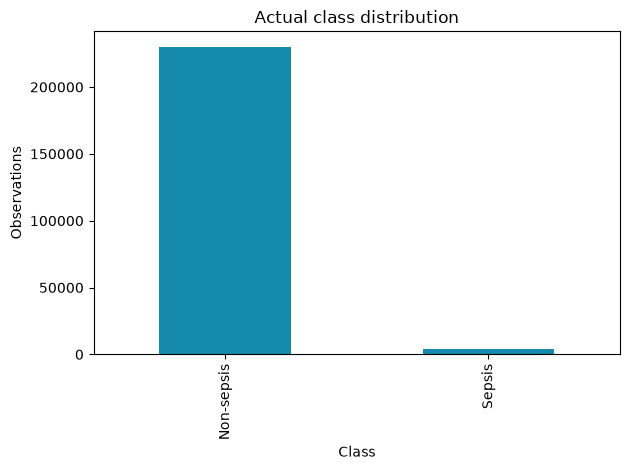

In [3]:
class_counts = data['SepsisLabel'].map({0: 'Non-sepsis', 1: 'Sepsis'}).value_counts().rename_axis('Class').to_frame('Observations')
display(class_counts)
class_counts.plot(kind='bar', legend=False, color=['#168aad', '#d1495b'], title='Actual class distribution')
plt.ylabel('Observations'); plt.tight_layout(); plt.show()

## Class-wise metrics
Recall for non-sepsis is specificity. Recall for sepsis measures how many actual sepsis cases are detected.

In [4]:
print(classification_report(data['SepsisLabel'], data['prediction'], target_names=['Non-sepsis', 'Sepsis'], digits=4, zero_division=0))
print('Overall accuracy:', round(accuracy_score(data['SepsisLabel'], data['prediction']), 4))

              precision    recall  f1-score   support

  Non-sepsis     0.9884    0.9506    0.9692    230108
      Sepsis     0.1258    0.3901    0.1903      4194

    accuracy                         0.9406    234302
   macro avg     0.5571    0.6703    0.5797    234302
weighted avg     0.9730    0.9406    0.9552    234302

Overall accuracy: 0.9406


Confusion matrix [non-sepsis, sepsis]:


,Predicted non-sepsis,Predicted sepsis
Actual non-sepsis,218744,11364
Actual sepsis,2558,1636


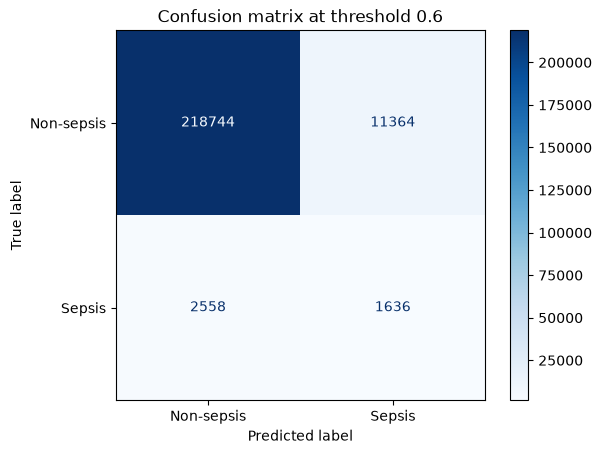

In [5]:
cm = confusion_matrix(data['SepsisLabel'], data['prediction'], labels=[0, 1])
print('Confusion matrix [non-sepsis, sepsis]:')
display(pd.DataFrame(cm, index=['Actual non-sepsis', 'Actual sepsis'], columns=['Predicted non-sepsis', 'Predicted sepsis']))
ConfusionMatrixDisplay(cm, display_labels=['Non-sepsis', 'Sepsis']).plot(cmap='Blues')
plt.title(f'Confusion matrix at threshold {THRESHOLD}')
plt.show()

## Threshold comparison
Lower thresholds generally increase sepsis recall but also increase false alerts. This table is for analysis only; it does not change the production threshold.

In [6]:
from sklearn.metrics import precision_score, recall_score, f1_score
rows = []
for threshold in [0.50, 0.55, 0.60, 0.65, 0.70, 0.75]:
    pred = (data['probability'] >= threshold).astype(int)
    rows.append({'Threshold': threshold, 'Accuracy': accuracy_score(data['SepsisLabel'], pred), 'Non-sepsis recall / specificity': recall_score(data['SepsisLabel'], pred, pos_label=0), 'Sepsis precision': precision_score(data['SepsisLabel'], pred, zero_division=0), 'Sepsis recall': recall_score(data['SepsisLabel'], pred, zero_division=0), 'Sepsis F1': f1_score(data['SepsisLabel'], pred, zero_division=0)})
threshold_table = pd.DataFrame(rows)
display(threshold_table.round(4))

,Threshold,Accuracy,Non-sepsis recall / specificity,Sepsis precision,Sepsis recall,Sepsis F1
0,0.50,0.9128,0.9207,0.0999,0.4831,0.1655
1,0.55,0.9273,0.9362,0.1110,0.4371,0.1771
2,0.60,0.9406,0.9506,0.1258,0.3901,0.1903
3,0.65,0.9521,0.9632,0.1450,0.3426,0.2038
4,0.70,0.9616,0.9740,0.1658,0.2835,0.2092
5,0.75,0.9699,0.9835,0.1975,0.2227,0.2093


## Interpretation
The model is a binary classifier. It does not prove that a feature caused sepsis; it estimates risk from the patient observations. Non-sepsis performance is represented mainly by specificity, while sepsis performance is represented by recall, precision, and F1.